# Proyek Analisis Data: Kualitas Udara Stasiun Dongsi, Beijing (PRSA)

- **Nama:** [Sarah Taqiyah]
- **Email:** [saraahhezz173@gmail.com]
- **ID Dicoding:** [DS001B6X1976]

**Dataset:** *Beijing Multi-Site Air-Quality Data* (PRSA), stasiun **Dongsi**, data per jam, 1 Maret 2013 – 28 Februari 2017.

## Menentukan Pertanyaan Bisnis

Konteks: pemerintah kota atau dinas lingkungan hidup perlu tahu **kapan** dan **dalam kondisi cuaca apa** polusi PM2.5 paling parah, supaya peringatan dini dan pembatasan emisi bisa dijadwalkan tepat sasaran.

**Pertanyaan 1 (pola waktu)**
> Selama periode Maret 2013 – Februari 2017, pada bulan dan jam berapa rata-rata PM2.5 di stasiun Dongsi paling tinggi, dan berapa persen hari yang masuk tiap kategori kualitas udara di setiap periode Maret–Februari?

**Pertanyaan 2 (faktor meteorologi)**
> Selama periode Maret 2013 – Februari 2017, bagaimana perbedaan rata-rata PM2.5 menurut kecepatan angin dan arah angin, dan kombinasi mana yang menghasilkan PM2.5 tertinggi?

| Elemen SMART | Q1 | Q2 |
|---|---|---|
| Specific | PM2.5 di satu stasiun (Dongsi); dimensi bulan, jam, kategori harian | PM2.5 terhadap kecepatan dan arah angin |
| Measurable | Rata-rata µg/m³, % hari per kategori | Rata-rata µg/m³, % jam di atas 75 µg/m³ per kombinasi |
| Action-oriented | Menjadwalkan advisori dan pembatasan emisi musiman | Memicu peringatan dini saat angin lemah dan arah dari sektor tertentu |
| Relevant | Tujuan utama: menekan paparan PM2.5 | Sama |
| Time-bound | 1 Mar 2013 – 28 Feb 2017 (4 periode penuh Maret–Februari) | Sama |

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Data Wrangling

### Gathering Data

Data dimuat dari berkas CSV asli (satu stasiun, data per jam).

In [2]:
from pathlib import Path

NAMA_FILE = "PRSA_Data_Dongsi_20130301-20170228.csv"

# Cari berkas data di beberapa lokasi umum agar notebook tetap jalan
# walau dibuka dari folder lain (VS Code, Jupyter, Colab).
kandidat = [
    Path("data") / NAMA_FILE,              # dijalankan dari folder submission
    Path(NAMA_FILE),                       # CSV satu folder dengan notebook
    Path("..") / "data" / NAMA_FILE,       # notebook dipindah ke subfolder
    Path("submission/data") / NAMA_FILE,   # dijalankan dari folder induk
    Path("/content") / NAMA_FILE,          # Google Colab (upload manual)
    Path("/content/data") / NAMA_FILE,
]
DATA_PATH = next((p for p in kandidat if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Berkas '{NAMA_FILE}' tidak ditemukan.\n"
        f"Folder kerja saat ini: {Path.cwd()}\n"
        "Pastikan folder 'data' ikut terekstrak dari zip, atau jalankan Jupyter dari folder 'submission'."
    )

# Folder keluaran: <folder submission>/dashboard
DATA_ABS = DATA_PATH.resolve()
BASE_DIR = DATA_ABS.parent.parent if DATA_ABS.parent.name == "data" else DATA_ABS.parent
OUT_DIR = BASE_DIR / "dashboard"
OUT_DIR.mkdir(exist_ok=True)

print("Membaca data dari:", DATA_PATH.resolve())
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

Membaca data dari: /content/PRSA_Data_Dongsi_20130301-20170228.csv
(35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.00,9.00,3.00,17.00,300.00,89.00,-0.50,"1,024.50",-21.40,0.00,NNW,5.70,Dongsi
1,2,2013,3,1,1,4.00,4.00,3.00,16.00,300.00,88.00,-0.70,"1,025.10",-22.10,0.00,NW,3.90,Dongsi
2,3,2013,3,1,2,7.00,7.00,NaN,17.00,300.00,60.00,-1.20,"1,025.30",-24.60,0.00,NNW,5.30,Dongsi
3,4,2013,3,1,3,3.00,3.00,5.00,18.00,NaN,NaN,-1.40,"1,026.20",-25.50,0.00,N,4.90,Dongsi
4,5,2013,3,1,4,3.00,3.00,7.00,NaN,200.00,84.00,-1.90,"1,027.10",-24.50,0.00,NNW,3.20,Dongsi


**Insight:**
- Terdapat 35.064 baris dan 18 kolom. Kolom waktu terpisah menjadi `year`, `month`, `day`, `hour`.
- Hanya ada satu stasiun (`Dongsi`), jadi analisis geospasial dan RFM **tidak relevan** untuk dataset ini. Teknik lanjutan yang dipakai adalah *manual grouping* dan *binning*.

### Assessing Data

**1. Tipe data, kelengkapan timestamp, dan duplikasi**

In [3]:
df.info()
print("Baris duplikat penuh      :", df.duplicated().sum())
print("Duplikat kunci waktu      :", df.duplicated(["year", "month", "day", "hour"]).sum())
waktu = pd.to_datetime(df[["year", "month", "day", "hour"]])
jam_seharusnya = int((waktu.max() - waktu.min()).total_seconds() / 3600) + 1
print("Rentang waktu             :", waktu.min(), "s/d", waktu.max())
print("Jumlah jam seharusnya     :", jam_seharusnya, "| jumlah baris:", len(df))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34314 non-null  float64
 6   PM10     34511 non-null  float64
 7   SO2      34401 non-null  float64
 8   NO2      33463 non-null  float64
 9   CO       31867 non-null  float64
 10  O3       34400 non-null  float64
 11  TEMP     35044 non-null  float64
 12  PRES     35044 non-null  float64
 13  DEWP     35044 non-null  float64
 14  RAIN     35044 non-null  float64
 15  wd       34986 non-null  object 
 16  WSPM     35050 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB
Baris duplikat penuh      : 0
Duplikat kunci waktu      : 0
Rentang 

**2. Missing value**

In [4]:
mv = pd.DataFrame({"jumlah": df.isna().sum(), "persen": df.isna().mean() * 100})
mv[mv["jumlah"] > 0].sort_values("jumlah", ascending=False)

,jumlah,persen
CO,3197,9.12
NO2,1601,4.57
PM2.5,750,2.14
O3,664,1.89
SO2,663,1.89
PM10,553,1.58
wd,78,0.22
TEMP,20,0.06
PRES,20,0.06
DEWP,20,0.06


In [5]:
# Panjang celah (jam berturut-turut) missing terpanjang per kolom
def celah_terpanjang(s):
    m = s.isna()
    grup = (m != m.shift()).cumsum()
    return int(m.groupby(grup).sum().max())

for kol in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]:
    print(f"{kol:6s} celah terpanjang: {celah_terpanjang(df[kol]):5d} jam")

PM2.5  celah terpanjang:    58 jam
PM10   celah terpanjang:    57 jam
SO2    celah terpanjang:    57 jam
NO2    celah terpanjang:   900 jam
CO     celah terpanjang:  1517 jam
O3     celah terpanjang:    57 jam


**3. Invalid/inconsistent value: PM2.5 seharusnya tidak melebihi PM10**

PM2.5 adalah bagian dari PM10, sehingga PM2.5 > PM10 secara fisik janggal (kecuali galat instrumen).

In [6]:
mask = df["PM2.5"] > df["PM10"]
selisih = (df.loc[mask, "PM2.5"] - df.loc[mask, "PM10"])
print("Baris PM2.5 > PM10 :", mask.sum(), f"({mask.mean()*100:.1f}%)")
print(selisih.describe())

Baris PM2.5 > PM10 : 2156 (6.1%)
count   2,156.00
mean       27.43
std        27.71
min         1.00
25%         8.00
50%        20.00
75%        38.00
max       270.00
dtype: float64


**4. Outlier dan nilai batas**

In [7]:
print("PM2.5 > 500 µg/m³  :", (df["PM2.5"] > 500).sum(), "baris")
print("CO == 10000        :", (df["CO"] == 10000).sum(), "baris (kemungkinan batas atas sensor)")
print("RAIN > 20 mm       :", (df["RAIN"] > 20).sum(), "baris")
print("WSPM max           :", df["WSPM"].max(), "m/s")
df[["PM2.5", "PM10", "WSPM", "TEMP"]].describe()

PM2.5 > 500 µg/m³  : 112 baris
CO == 10000        : 10 baris (kemungkinan batas atas sensor)
RAIN > 20 mm       : 13 baris
WSPM max           : 10.5 m/s


,PM2.5,PM10,WSPM,TEMP
count,"34,314.00","34,511.00","35,050.00","35,044.00"
mean,86.19,110.34,1.86,13.67
std,86.58,98.22,1.28,11.46
min,3.00,2.00,0.00,-16.80
25%,22.00,38.00,1.00,3.10
50%,61.00,86.00,1.50,14.60
75%,119.00,151.00,2.40,23.50
max,737.00,955.00,10.50,41.10


**5. Inconsistent value: presisi desimal SO2 dan O3**

In [8]:
for kol in ["SO2", "O3", "NO2", "PM2.5"]:
    v = df[kol].dropna()
    print(f"{kol:6s} nilai non-integer: {(v % 1 != 0).sum():5d} dari {len(v)}")

SO2    nilai non-integer:  1421 dari 34401
O3     nilai non-integer:   996 dari 34400
NO2    nilai non-integer:  1511 dari 33463
PM2.5  nilai non-integer:    17 dari 34314


**6. Cakupan waktu tiap tahun kalender**

Karena data mulai Maret 2013 dan berakhir Februari 2017, tahun kalender 2013 dan 2017 tidak lengkap.

In [9]:
df.groupby("year")["month"].agg(bulan_awal="min", bulan_akhir="max", jumlah_jam="size")

,bulan_awal,bulan_akhir,jumlah_jam
year,,,
2013,3,12,7344
2014,1,12,8760
2015,1,12,8760
2016,1,12,8784
2017,1,2,1416


**Ringkasan temuan Assessing Data dan rencana Cleaning**

| # | Masalah | Temuan | Tindakan di tahap Cleaning |
|---|---|---|---|
| 1 | Missing value | CO ±9,1%, NO2 ±4,6%, PM2.5 ±2,1%, `wd` 78 baris. Celah CO dan NO2 sangat panjang (ratusan hingga ribuan jam). | PM2.5: interpolasi waktu **hanya untuk celah pendek (≤ 6 jam)**. CO dan NO2 **tidak** diisi dan tidak dipakai di analisis utama. `wd` kosong dikeluarkan hanya pada analisis arah angin. |
| 2 | Nilai tidak konsisten secara logika | PM2.5 > PM10 pada ±6% baris | Diberi penanda `pm25_gt_pm10`, **tidak dihapus**. Dilakukan uji sensitivitas. |
| 3 | Outlier | PM2.5 > 500 pada 112 baris | **Dipertahankan** karena kemungkinan besar episode polusi nyata. Menghapusnya akan membiaskan hasil ke bawah. |
| 4 | Presisi tidak seragam | SO2 dan O3 punya ribuan nilai non-integer padahal mayoritas bulat | Didokumentasikan. SO2 dan O3 tidak dipakai di analisis utama. |
| 5 | Periode tidak lengkap | Tahun kalender 2013 dan 2017 parsial | Dibuat kolom `periode` (Maret–Februari) agar 4 periode sebanding. |

### Cleaning Data

In [10]:
dc = df.copy()
dc["datetime"] = pd.to_datetime(dc[["year", "month", "day", "hour"]])
dc = dc.sort_values("datetime").reset_index(drop=True)

# 1) Penanda inkonsistensi PM2.5 vs PM10 (tidak dihapus)
dc["pm25_gt_pm10"] = (dc["PM2.5"] > dc["PM10"]).astype(int)

# 2) Interpolasi PM2.5 hanya untuk celah pendek (<= 6 jam)
sebelum = dc["PM2.5"].isna().sum()
dc["PM2.5"] = (dc.set_index("datetime")["PM2.5"]
                 .interpolate(method="time", limit=6, limit_area="inside")
                 .to_numpy())
print(f"Missing PM2.5: {sebelum} -> {dc['PM2.5'].isna().sum()}")

# 3) Buang kolom konstan / indeks
dc = dc.drop(columns=["No", "station"])

Missing PM2.5: 750 -> 324


**Fitur turunan** (manual grouping dan binning, aturan ditetapkan di awal, bukan dari hasil data):

In [11]:
# Musim meteorologis (Belahan Bumi Utara)
musim_map = {12: "Dingin", 1: "Dingin", 2: "Dingin", 3: "Semi", 4: "Semi", 5: "Semi",
             6: "Panas", 7: "Panas", 8: "Panas", 9: "Gugur", 10: "Gugur", 11: "Gugur"}
dc["musim"] = dc["month"].map(musim_map)

# Periode Maret-Februari
th = np.where(dc["month"] >= 3, dc["year"], dc["year"] - 1)
dc["periode"] = [f"Mar {t}-Feb {t+1}" for t in th]

# Binning kecepatan angin (m/s)
bin_angin = [-0.01, 1, 2, 3, 5, np.inf]
lab_angin = ["≤1 (sangat lemah)", "1-2 (lemah)", "2-3 (sedang)", "3-5 (cukup kuat)", ">5 (kuat)"]
dc["kelas_angin"] = pd.cut(dc["WSPM"], bins=bin_angin, labels=lab_angin)

# Manual grouping arah angin -> kuadran (derajat kompas, batas kiri-tertutup)
derajat = {"N": 0, "NNE": 22.5, "NE": 45, "ENE": 67.5, "E": 90, "ESE": 112.5, "SE": 135, "SSE": 157.5,
           "S": 180, "SSW": 202.5, "SW": 225, "WSW": 247.5, "W": 270, "WNW": 292.5, "NW": 315, "NNW": 337.5}
dc["kuadran"] = pd.cut(dc["wd"].map(derajat), bins=[0, 90, 180, 270, 360],
                       labels=["Utara-Timur Laut", "Timur-Tenggara", "Selatan-Barat Daya", "Barat-Barat Laut"],
                       right=False, include_lowest=True)

# Blok waktu
dc["blok_waktu"] = pd.cut(dc["hour"], bins=[-1, 5, 11, 17, 23],
                          labels=["Dini hari (0-5)", "Pagi (6-11)", "Siang-sore (12-17)", "Malam (18-23)"])
dc["tanggal"] = dc["datetime"].dt.normalize()
dc[["datetime", "PM2.5", "WSPM", "wd", "musim", "periode", "kelas_angin", "kuadran", "blok_waktu"]].head()

,datetime,PM2.5,WSPM,wd,musim,periode,kelas_angin,kuadran,blok_waktu
0,2013-03-01 00:00:00,9.00,5.70,NNW,Semi,Mar 2013-Feb 2014,>5 (kuat),Barat-Barat Laut,Dini hari (0-5)
1,2013-03-01 01:00:00,4.00,3.90,NW,Semi,Mar 2013-Feb 2014,3-5 (cukup kuat),Barat-Barat Laut,Dini hari (0-5)
2,2013-03-01 02:00:00,7.00,5.30,NNW,Semi,Mar 2013-Feb 2014,>5 (kuat),Barat-Barat Laut,Dini hari (0-5)
3,2013-03-01 03:00:00,3.00,4.90,N,Semi,Mar 2013-Feb 2014,3-5 (cukup kuat),Utara-Timur Laut,Dini hari (0-5)
4,2013-03-01 04:00:00,3.00,3.20,NNW,Semi,Mar 2013-Feb 2014,3-5 (cukup kuat),Barat-Barat Laut,Dini hari (0-5)


**Uji sensitivitas**: apakah baris dengan PM2.5 > PM10 mengubah kesimpulan?

In [12]:
semua = dc.groupby("month")["PM2.5"].mean()
bersih = dc[dc["pm25_gt_pm10"] == 0].groupby("month")["PM2.5"].mean()
print("3 bulan tertinggi (semua data)  :", semua.nlargest(3).index.tolist())
print("3 bulan tertinggi (tanpa flag)  :", bersih.nlargest(3).index.tolist())
a1 = dc.groupby("kelas_angin", observed=True)["PM2.5"].mean()
a2 = dc[dc["pm25_gt_pm10"] == 0].groupby("kelas_angin", observed=True)["PM2.5"].mean()
print("Urutan kelas angin sama?        :", a1.sort_values().index.tolist() == a2.sort_values().index.tolist())

3 bulan tertinggi (semua data)  : [12, 1, 3]
3 bulan tertinggi (tanpa flag)  : [12, 3, 1]
Urutan kelas angin sama?        : True


**Simpan data bersih untuk dashboard**

In [13]:
kolom = ["datetime", "tanggal", "PM2.5", "TEMP", "WSPM", "wd", "month", "hour", "musim", "periode",
         "kelas_angin", "kuadran", "blok_waktu", "pm25_gt_pm10"]
dc[kolom].to_csv(OUT_DIR / "main_data.csv", index=False)
print("Tersimpan di:", (OUT_DIR / "main_data.csv").resolve(), f"({os.path.getsize(OUT_DIR / 'main_data.csv') / 1e6:.1f} MB)")

Tersimpan di: /content/dashboard/main_data.csv (4.4 MB)


## Exploratory Data Analysis (EDA)

### Q1: Pola waktu PM2.5

In [14]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
bulanan = dc.groupby("month")["PM2.5"].agg(rata2="mean", median="median", n="count")
bulanan.index = nama_bulan
print("Rata-rata keseluruhan:", round(dc["PM2.5"].mean(), 1))
bulanan.round(1)

Rata-rata keseluruhan: 86.1


,rata2,median,n
Jan,100.30,67.00,2976
Feb,94.90,49.00,2709
Mar,100.20,76.00,2972
Apr,77.30,66.00,2880
Mei,69.50,55.00,2961
Jun,73.40,57.00,2791
Jul,80.30,68.00,2863
Agu,58.60,48.00,2940
Sep,67.00,53.00,2867
Okt,98.30,63.00,2936


In [15]:
# Apakah pola bulanan konsisten antar periode? (menguji agar tidak ditentukan satu tahun saja)
pivot_bp = dc.pivot_table(index="month", columns="periode", values="PM2.5", aggfunc="mean")
pivot_bp.index = nama_bulan
print("Bulan tertinggi tiap periode:", pivot_bp.idxmax().to_dict())
pivot_bp.round(1)

Bulan tertinggi tiap periode: {'Mar 2013-Feb 2014': 'Feb', 'Mar 2014-Feb 2015': 'Okt', 'Mar 2015-Feb 2016': 'Des', 'Mar 2016-Feb 2017': 'Des'}


periode,Mar 2013-Feb 2014,Mar 2014-Feb 2015,Mar 2015-Feb 2016,Mar 2016-Feb 2017
Jan,104.10,101.00,69.40,126.90
Feb,154.20,109.00,43.20,75.10
Mar,108.40,99.90,93.30,99.20
Apr,65.30,89.90,77.20,77.00
Mei,91.40,63.70,59.50,63.40
Jun,108.70,57.70,66.40,61.90
Jul,73.40,98.90,69.10,79.40
Agu,64.90,69.50,49.60,51.00
Sep,85.30,67.70,54.40,60.60
Okt,102.60,116.90,80.10,93.50


In [16]:
per_jam = dc.groupby("hour")["PM2.5"].mean()
print("Jam tertinggi:", per_jam.idxmax(), "->", round(per_jam.max(), 1))
print("Jam terendah :", per_jam.idxmin(), "->", round(per_jam.min(), 1))
print("Rasio tertinggi/terendah:", round(per_jam.max() / per_jam.min(), 2))
dc.groupby("blok_waktu", observed=True)["PM2.5"].mean().round(1)

Jam tertinggi: 22 -> 97.6
Jam terendah : 16 -> 77.9
Rasio tertinggi/terendah: 1.25


,PM2.5
blok_waktu,
Dini hari (0-5),92.80
Pagi (6-11),80.30
Siang-sore (12-17),79.00
Malam (18-23),92.40


In [17]:
# Rata-rata vs median vs ekor distribusi per musim: apakah selisih musim dipicu episode ekstrem?
g = dc.groupby("musim")["PM2.5"]
musim_stat = pd.DataFrame({"rata2": g.mean(), "median": g.median(), "p90": g.quantile(0.9),
                           "pct_jam_>150": g.apply(lambda s: (s > 150).mean() * 100)}).loc[["Semi", "Panas", "Gugur", "Dingin"]]
display(musim_stat.round(1))

# Paruh tahun dingin (Okt-Mar) vs hangat (Apr-Sep) di tiap periode
dc["paruh"] = np.where(dc["month"].isin([10, 11, 12, 1, 2, 3]), "Okt-Mar", "Apr-Sep")
dc.pivot_table(index="periode", columns="paruh", values="PM2.5", aggfunc="mean").round(1)

,rata2,median,p90,pct_jam_>150
musim,,,,
Semi,82.40,64.00,178.00,14.20
Panas,70.70,58.00,147.00,9.10
Gugur,88.40,61.00,217.00,19.90
Dingin,103.00,60.00,261.00,25.40


paruh,Apr-Sep,Okt-Mar
periode,,
Mar 2013-Feb 2014,81.30,105.70
Mar 2014-Feb 2015,74.60,93.80
Mar 2015-Feb 2016,62.70,95.80
Mar 2016-Feb 2017,65.30,109.40


In [18]:
# Amplitude pola harian per musim (rata-rata jam tertinggi / terendah)
for s in ["Dingin", "Gugur", "Semi", "Panas"]:
    h = dc[dc["musim"] == s].groupby("hour")["PM2.5"].mean()
    print(f"{s:7s} puncak jam {h.idxmax():2d}, terendah jam {h.idxmin():2d}, rasio {h.max()/h.min():.2f}")

Dingin  puncak jam 23, terendah jam 10, rasio 1.57
Gugur   puncak jam 22, terendah jam  8, rasio 1.42
Semi    puncak jam 11, terendah jam 18, rasio 1.21
Panas   puncak jam  9, terendah jam 17, rasio 1.16


**Kategori kualitas udara harian** (binning rata-rata harian PM2.5 dengan titik batas 35/75/115/150/250 µg/m³).

> Catatan verifikasi: titik batas ini saya ambil dari ingatan terhadap standar AQI China (HJ 633-2012) dan **perlu diverifikasi** terhadap dokumen resmi sebelum disitir dalam laporan. Syarat minimal 20 jam valid per hari juga perlu diverifikasi. Nilai ini saya tetapkan sebagai asumsi kerja.

In [19]:
MIN_JAM = 20
harian = (dc.groupby("tanggal").agg(pm25=("PM2.5", "mean"), n=("PM2.5", "count"), periode=("periode", "first"))
            .query("n >= @MIN_JAM"))
print(f"Hari valid: {len(harian)} dari {dc['tanggal'].nunique()}")

batas = [0, 35, 75, 115, 150, 250, np.inf]
kategori = ["Baik sekali (≤35)", "Baik (35-75)", "Ringan (75-115)", "Sedang (115-150)", "Berat (150-250)", "Sangat berat (>250)"]
harian["kategori"] = pd.cut(harian["pm25"], bins=batas, labels=kategori)

share = (harian.groupby("periode")["kategori"].value_counts(normalize=True).unstack().reindex(columns=kategori) * 100)
print("\n% hari per kategori (keseluruhan):")
print((harian["kategori"].value_counts(normalize=True).reindex(kategori) * 100).round(1))
print("\n% hari > 75 µg/m³ per periode:")
print((harian.assign(lebih=harian["pm25"] > 75).groupby("periode")["lebih"].mean() * 100).round(1))
share.round(1)

Hari valid: 1438 dari 1461

% hari per kategori (keseluruhan):
kategori
Baik sekali (≤35)     27.50
Baik (35-75)          29.10
Ringan (75-115)       18.60
Sedang (115-150)      10.40
Berat (150-250)       10.00
Sangat berat (>250)    4.50
Name: proportion, dtype: float64

% hari > 75 µg/m³ per periode:
periode
Mar 2013-Feb 2014   49.20
Mar 2014-Feb 2015   43.40
Mar 2015-Feb 2016   37.10
Mar 2016-Feb 2017   44.00
Name: lebih, dtype: float64


kategori,Baik sekali (≤35),Baik (35-75),Ringan (75-115),Sedang (115-150),Berat (150-250),Sangat berat (>250)
periode,,,,,,
Mar 2013-Feb 2014,18.70,32.10,20.40,12.80,10.90,5.00
Mar 2014-Feb 2015,28.60,28.00,18.10,11.00,11.50,2.70
Mar 2015-Feb 2016,34.60,28.30,15.70,9.60,7.40,4.40
Mar 2016-Feb 2017,28.10,27.80,20.20,8.00,10.20,5.70


### Q2: Pengaruh kecepatan dan arah angin

In [20]:
angin = dc.groupby("kelas_angin", observed=True)["PM2.5"].agg(rata2="mean", median="median", n="count")
angin["pct_jam_>75"] = dc.assign(t=dc["PM2.5"] > 75).groupby("kelas_angin", observed=True)["t"].mean() * 100
angin.round(1)

,rata2,median,n,pct_jam_>75
kelas_angin,,,,
≤1 (sangat lemah),116.60,88.00,9502,56.30
1-2 (lemah),92.80,70.00,13822,46.10
2-3 (sedang),64.80,45.00,6131,32.40
3-5 (cukup kuat),41.40,20.00,4220,17.90
>5 (kuat),27.00,12.00,1051,8.90


In [21]:
arah = dc.groupby("wd")["PM2.5"].agg(rata2="mean", n="count").sort_values("rata2")
print("Jam dengan arah angin kosong dikeluarkan:", dc["wd"].isna().sum())
arah.round(1)

Jam dengan arah angin kosong dikeluarkan: 78


,rata2,n
wd,,
NW,34.20,2457
NNW,39.90,1689
WNW,44.70,1341
N,64.70,1861
W,72.70,979
WSW,75.60,1757
NNE,75.80,1920
SW,79.90,2458
SSW,86.50,1931


In [22]:
print("Korelasi PM2.5 vs WSPM  Pearson :", round(dc[["PM2.5", "WSPM"]].corr().iloc[0, 1], 2))
print("Korelasi PM2.5 vs WSPM  Spearman:", round(dc[["PM2.5", "WSPM"]].corr(method="spearman").iloc[0, 1], 2))
print("\nKorelasi PM2.5 vs TEMP (Pearson):", round(dc[["PM2.5", "TEMP"]].corr().iloc[0, 1], 2))

Korelasi PM2.5 vs WSPM  Pearson : -0.3
Korelasi PM2.5 vs WSPM  Spearman: -0.37

Korelasi PM2.5 vs TEMP (Pearson): -0.14


In [23]:
# Pengendalian faktor pengganggu (confounder): efek angin dalam tiap musim
silang = dc.pivot_table(index="kelas_angin", columns="musim", values="PM2.5", aggfunc="mean", observed=True)
silang = silang[["Semi", "Panas", "Gugur", "Dingin"]]
n_silang = dc.pivot_table(index="kelas_angin", columns="musim", values="PM2.5", aggfunc="count", observed=True)[["Semi", "Panas", "Gugur", "Dingin"]]
print("Sel dengan n terkecil:", int(n_silang.min().min()))
silang.round(1)

Sel dengan n terkecil: 49


musim,Semi,Panas,Gugur,Dingin
kelas_angin,,,,
≤1 (sangat lemah),107.50,75.80,116.30,162.10
1-2 (lemah),93.60,72.10,91.30,118.60
2-3 (sedang),75.00,68.00,52.10,56.30
3-5 (cukup kuat),57.00,51.70,23.50,24.50
>5 (kuat),39.20,41.10,16.40,17.50


## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada bulan dan jam berapa PM2.5 tertinggi, dan bagaimana sebaran kategori harian per periode?

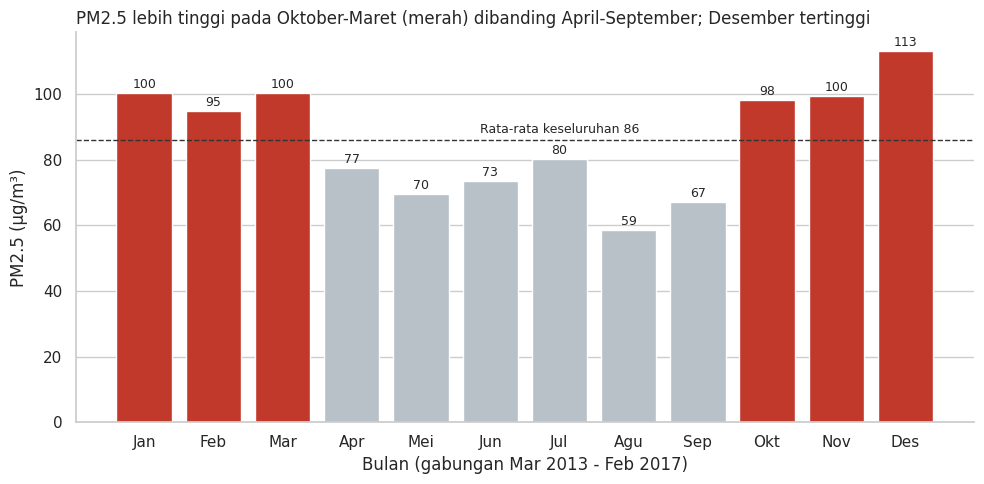

In [24]:
rata_all = dc["PM2.5"].mean()
m = dc.groupby("month")["PM2.5"].mean()
dingin = {10, 11, 12, 1, 2, 3}
fig, ax = plt.subplots(figsize=(10, 5))
warna = ["#C0392B" if i in dingin else "#B8C0C8" for i in m.index]
bars = ax.bar(nama_bulan, m.values, color=warna)
ax.axhline(rata_all, color="#333", ls="--", lw=1)
ax.text(6, rata_all + 2, f"Rata-rata keseluruhan {rata_all:.0f}", ha="center", fontsize=9)
for b, v in zip(bars, m.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}", ha="center", fontsize=9)
ax.set_title("PM2.5 lebih tinggi pada Oktober-Maret (merah) dibanding April-September; Desember tertinggi", loc="left", fontsize=12)
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_xlabel("Bulan (gabungan Mar 2013 - Feb 2017)")
sns.despine(); plt.tight_layout(); plt.show()

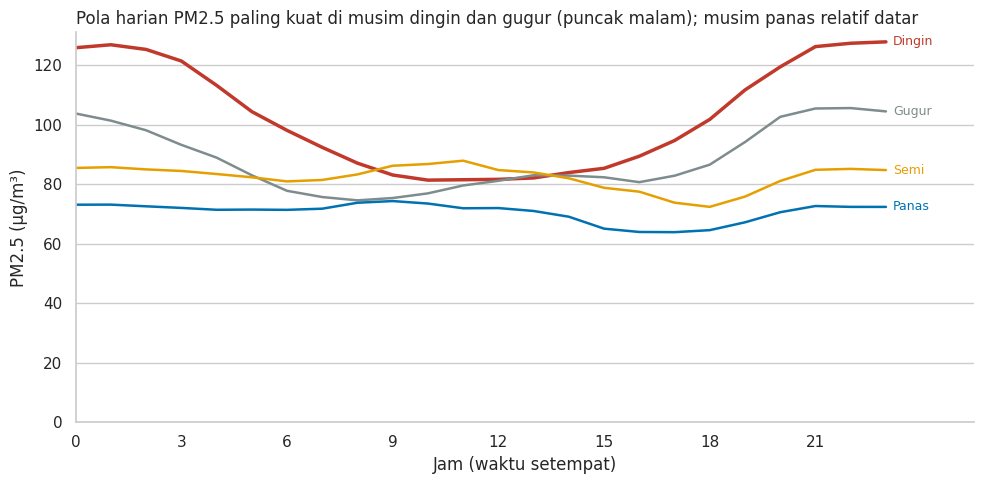

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
pal = {"Dingin": "#C0392B", "Semi": "#E69F00", "Panas": "#0072B2", "Gugur": "#7F8C8D"}
for s in ["Dingin", "Gugur", "Semi", "Panas"]:
    d = dc[dc["musim"] == s].groupby("hour")["PM2.5"].mean()
    ax.plot(d.index, d.values, color=pal[s], lw=2.5 if s == "Dingin" else 1.8, label=s)
    ax.text(23.2, d.values[-1], s, color=pal[s], va="center", fontsize=9)
ax.set_xticks(range(0, 24, 3)); ax.set_xlim(0, 25.5)
ax.set_title("Pola harian PM2.5 paling kuat di musim dingin dan gugur (puncak malam); musim panas relatif datar", loc="left", fontsize=12)
ax.set_xlabel("Jam (waktu setempat)"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_ylim(bottom=0)
sns.despine(); plt.tight_layout(); plt.show()

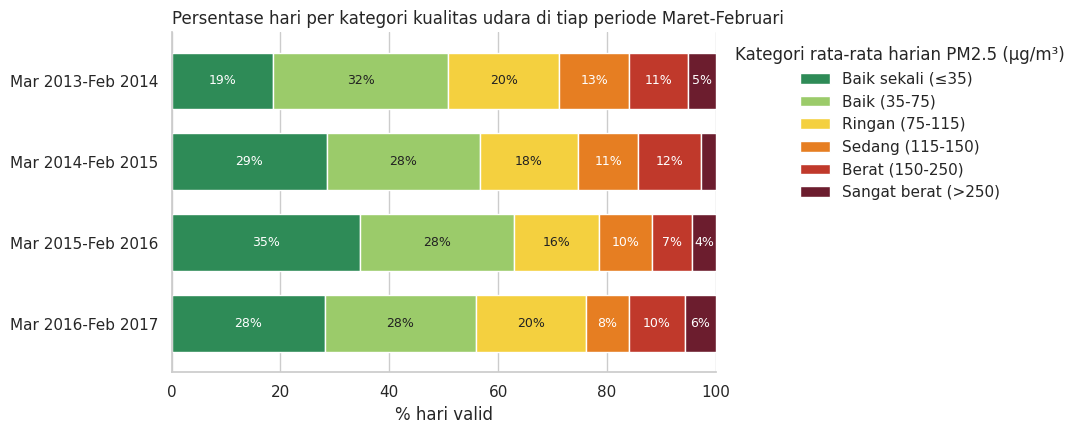

In [26]:
warna_kat = ["#2E8B57", "#9BCB6A", "#F4D03F", "#E67E22", "#C0392B", "#6C1D2E"]
ax = share.plot(kind="barh", stacked=True, color=warna_kat, figsize=(11, 4.5), width=0.7)
teks = ["white", "#222", "#222", "white", "white", "white"]
for cont, tc in zip(ax.containers, teks):
    ax.bar_label(cont, labels=[f"{v:.0f}%" if v >= 4 else "" for v in cont.datavalues],
                 label_type="center", fontsize=9, color=tc)
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_title("Persentase hari per kategori kualitas udara di tiap periode Maret-Februari", loc="left", fontsize=12)
ax.set_xlabel("% hari valid"); ax.set_ylabel("")
ax.legend(title="Kategori rata-rata harian PM2.5 (µg/m³)", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

**Insight Pertanyaan 1:**


- **Bulan:** Desember adalah bulan dengan rata-rata tertinggi (113,1 µg/m³), diikuti Januari (100,3), Maret (100,2), November (99,5), dan Oktober (98,3). Agustus terendah (58,6). Pola yang **konsisten** adalah paruh **Oktober-Maret lebih tinggi daripada April-September di keempat periode** (mis. 109,4 vs 65,3 pada Mar 2016-Feb 2017).
- **Peringatan:** bulan *tertentu* yang paling buruk **tidak stabil** antar periode (Februari, Oktober, Desember, Desember). Desember tinggi karena dua dari empat tahun sangat parah (161,2 pada 2015 dan 149,7 pada 2016), sedangkan Desember 2014 hanya 55,1. Urutan Januari/Maret juga bertukar pada uji sensitivitas. Jadi kesimpulan yang aman adalah *musim*, bukan *satu bulan*.
- **Rata-rata vs median:** median PM2.5 hampir sama di semua musim (58-64 µg/m³), tetapi rata-rata musim dingin 103,0 vs musim panas 70,7. Persentase jam dengan PM2.5 > 150 µg/m³ adalah 25,4% (dingin) vs 9,1% (panas). Artinya musim dingin tidak membuat kondisi "biasa" jauh lebih buruk. Yang berbeda adalah **frekuensi episode polusi berat**.
- **Jam:** rata-rata tertinggi pukul 22:00 (97,6) dan terendah pukul 16:00 (77,9), rasio hanya 1,25. Pola harian paling kuat di musim dingin (rasio 1,57; puncak pukul 23:00) dan paling datar di musim panas (rasio 1,16). Blok dini hari (92,8) dan malam (92,4) lebih tinggi daripada pagi (80,3) dan siang-sore (79,0).
- **Kategori harian** (1.438 hari valid): Baik sekali 27,5%, Baik 29,1%, Ringan 18,6%, Sedang 10,4%, Berat 10,0%, Sangat berat 4,5%. Persentase hari di atas 75 µg/m³ per periode: 49,2% → 43,4% → 37,1% → 44,0%. **Tidak ada tren menurun yang monoton**: periode 2015-16 terbaik, lalu memburuk lagi di 2016-17. Empat titik data tidak cukup untuk menyimpulkan tren jangka panjang.

### Pertanyaan 2: Bagaimana PM2.5 berbeda menurut kecepatan dan arah angin?

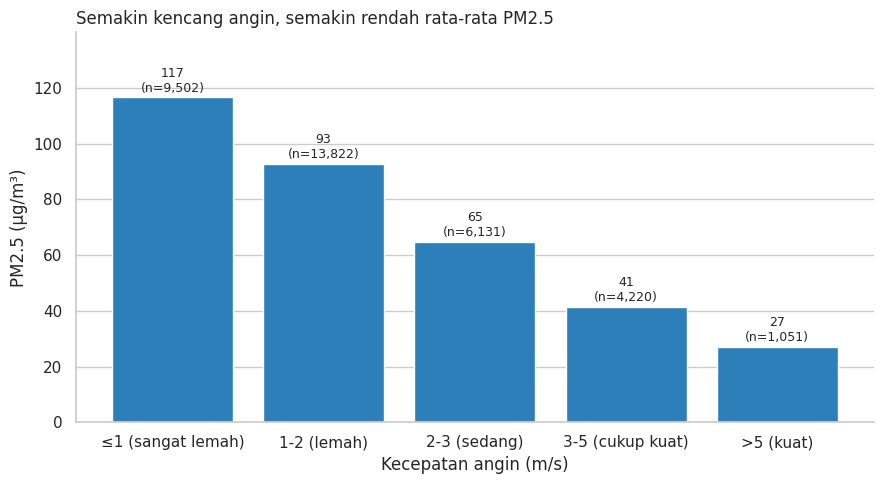

In [27]:
a = dc.groupby("kelas_angin", observed=True)["PM2.5"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(a.index.astype(str), a["mean"], color="#2C7FB8")
for b, (mu, n) in zip(bars, a.values):
    ax.text(b.get_x() + b.get_width() / 2, mu + 2, f"{mu:.0f}\n(n={int(n):,})", ha="center", fontsize=9)
ax.set_title("Semakin kencang angin, semakin rendah rata-rata PM2.5", loc="left", fontsize=12)
ax.set_xlabel("Kecepatan angin (m/s)"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_ylim(0, a["mean"].max() * 1.2)
sns.despine(); plt.tight_layout(); plt.show()

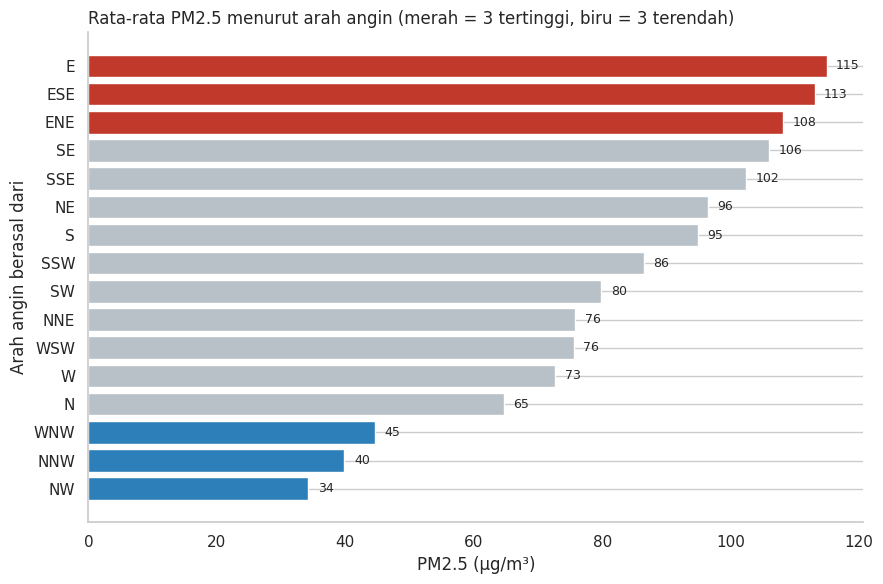

In [28]:
ar = dc.groupby("wd")["PM2.5"].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
warna = ["#C0392B" if i >= len(ar) - 3 else "#2C7FB8" if i < 3 else "#B8C0C8" for i in range(len(ar))]
ax.barh(ar.index, ar.values, color=warna)
for y, v in enumerate(ar.values):
    ax.text(v + 1.5, y, f"{v:.0f}", va="center", fontsize=9)
ax.set_title("Rata-rata PM2.5 menurut arah angin (merah = 3 tertinggi, biru = 3 terendah)", loc="left", fontsize=12)
ax.set_xlabel("PM2.5 (µg/m³)"); ax.set_ylabel("Arah angin berasal dari")
sns.despine(); plt.tight_layout(); plt.show()

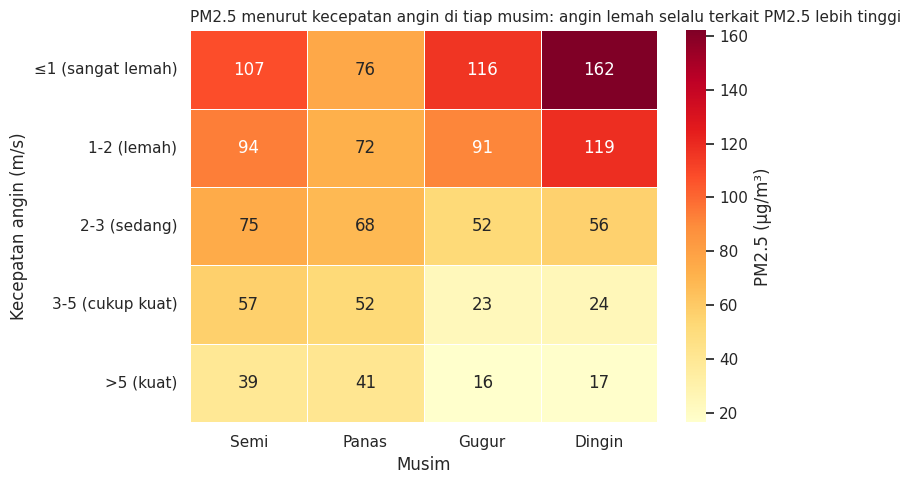

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(silang, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "PM2.5 (µg/m³)"}, linewidths=0.5, ax=ax)
ax.set_title("PM2.5 menurut kecepatan angin di tiap musim: angin lemah selalu terkait PM2.5 lebih tinggi", loc="left", fontsize=11)
ax.set_xlabel("Musim"); ax.set_ylabel("Kecepatan angin (m/s)")
plt.tight_layout(); plt.show()

**Insight Pertanyaan 2:**


- **Kecepatan angin:** hubungan menurun jelas dan berurutan. Pada angin ≤1 m/s rata-rata PM2.5 adalah 116,6 µg/m³ (56,3% jam di atas 75), sedangkan pada angin >5 m/s hanya 27,0 (8,9% jam di atas 75). Korelasi negatif sedang (Pearson -0,30; Spearman -0,37), karena efeknya paling besar di rentang angin rendah (tidak linear).
- **Arah angin:** tertinggi saat angin berasal dari E (114,9), ESE (113,1), dan ENE (108,1). Terendah dari NW (34,2), NNW (39,9), dan WNW (44,7).
- **Faktor pengganggu:** arah dan kecepatan angin saling terkait. Angin NW rata-rata 3,34 m/s, sedangkan angin E hanya 1,30 m/s. Sebagian selisih antar-arah adalah efek kecepatan, sehingga arah tidak boleh dibaca terpisah (lihat Analisis Lanjutan).
- **Per musim:** angin lemah selalu berkaitan dengan PM2.5 lebih tinggi, tetapi besarnya berbeda. Dari ≤1 m/s ke >5 m/s, PM2.5 turun dari 162,1 ke 17,5 di musim dingin, namun hanya dari 75,8 ke 41,1 di musim panas. Sel terkecil (musim panas, >5 m/s) hanya n=49 jam.

## Analisis Lanjutan: Manual Grouping dan Binning (Matriks Risiko Angin)

Tujuan: menggabungkan kedua dimensi Q2 (kecepatan angin hasil *binning* dan kuadran arah hasil *manual grouping*) menjadi **matriks risiko**, yaitu persentase jam dengan PM2.5 > 75 µg/m³.

> Catatan: 75 µg/m³ adalah batas harian. Di sini dipakai pada data per jam sebagai **indikator jam tinggi**, bukan pelanggaran standar resmi.

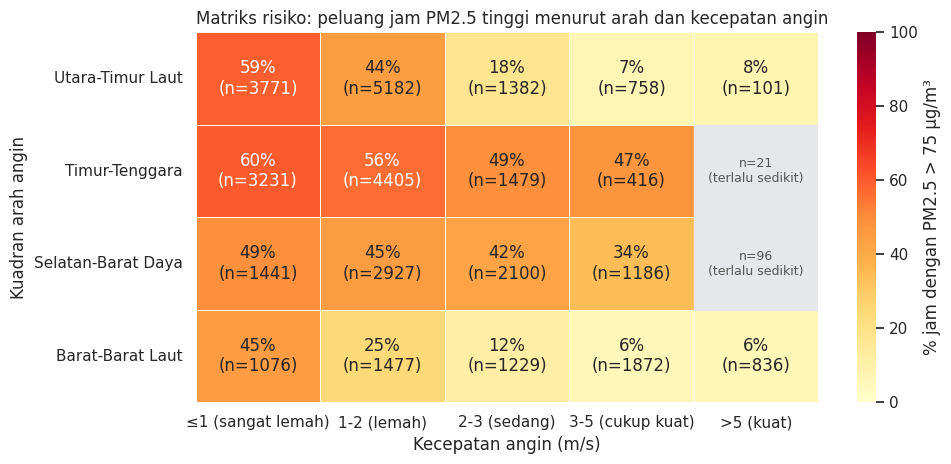

Sel dengan n < 100 perlu ditafsirkan hati-hati: 2


In [30]:
dk = dc.dropna(subset=["kuadran"]).copy()
dk["tinggi"] = dk["PM2.5"] > 75
risiko = dk.pivot_table(index="kuadran", columns="kelas_angin", values="tinggi", aggfunc="mean", observed=True) * 100
jumlah = dk.pivot_table(index="kuadran", columns="kelas_angin", values="tinggi", aggfunc="count", observed=True)
label = risiko.round(0).astype(int).astype(str) + "%\n(n=" + jumlah.astype(int).astype(str) + ")"

kecil = jumlah < 100
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(risiko, annot=label, fmt="", cmap="YlOrRd", vmin=0, vmax=100, mask=kecil,
            cbar_kws={"label": "% jam dengan PM2.5 > 75 µg/m³"}, linewidths=0.5, linecolor="white", ax=ax)
for i in range(kecil.shape[0]):
    for j in range(kecil.shape[1]):
        if kecil.iloc[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color="#E5E7EA", zorder=2))
            ax.text(j + 0.5, i + 0.5, f"n={jumlah.iloc[i, j]}\n(terlalu sedikit)", ha="center", va="center",
                    fontsize=9, color="#555", zorder=3)
ax.set_title("Matriks risiko: peluang jam PM2.5 tinggi menurut arah dan kecepatan angin", loc="left", fontsize=12)
ax.set_xlabel("Kecepatan angin (m/s)"); ax.set_ylabel("Kuadran arah angin")
plt.tight_layout(); plt.show()
print("Sel dengan n < 100 perlu ditafsirkan hati-hati:", int((jumlah < 100).sum().sum()))

**Insight Analisis Lanjutan:**


- Pada kecepatan angin 1-3 m/s, peluang jam dengan PM2.5 > 75 µg/m³ untuk kuadran **Timur-Tenggara** adalah 56% (1-2 m/s) dan 49% (2-3 m/s), jauh di atas kuadran **Barat-Barat Laut** (25% dan 12%). Pada 3-5 m/s selisihnya masih besar: 47% (Timur-Tenggara) vs 6% (Barat-Barat Laut). Jadi arah angin **tetap berpengaruh setelah kecepatan dikendalikan**, tidak hanya karena angin barat laut lebih kencang.
- Saat angin sangat lemah (≤1 m/s), semua kuadran berisiko tinggi (45%-60%), sehingga **angin lemah adalah faktor yang paling dominan**.
- Rata-rata PM2.5 menurut kuadran: Timur-Tenggara 110,8; Utara-Timur Laut 91,6; Selatan-Barat Daya 83,5; Barat-Barat Laut 43,7.
- Dua sel dengan n < 100 (mis. Timur-Tenggara pada >5 m/s, hanya 21 jam) **sengaja ditutup abu-abu** pada matriks dan tidak dijadikan dasar kesimpulan, karena persentasenya tidak stabil.

## Conclusion


**Kesimpulan Pertanyaan 1 (pola waktu):** Selama Mar 2013-Feb 2017, PM2.5 di Dongsi secara konsisten lebih tinggi pada Oktober-Maret (rata-rata per periode 93,8-109,4 µg/m³) daripada April-September (62,7-81,3). Desember memiliki rata-rata bulanan tertinggi (113,1), tetapi bulan terburuk berganti antar periode. Perbedaan musim terutama berasal dari **episode berat yang lebih sering** di musim dingin (25,4% jam > 150 µg/m³ vs 9,1% di musim panas), bukan dari kondisi tipikal. Dalam sehari, PM2.5 tertinggi sekitar pukul 22:00 dan terendah sekitar pukul 16:00. Sebanyak 43,4% hari valid (624 dari 1.438) melampaui 75 µg/m³ dan tidak ada tren perbaikan monoton antar periode.

**Kesimpulan Pertanyaan 2 (angin):** PM2.5 turun tajam seiring naiknya kecepatan angin (116,6 pada ≤1 m/s vs 27,0 pada >5 m/s), dan angin dari sektor Timur-Tenggara berasosiasi dengan PM2.5 tertinggi. Efek arah bertahan setelah kecepatan dikendalikan (56% vs 25% jam tinggi pada 1-2 m/s). Kombinasi **angin lemah (≤2 m/s) dengan arah dari Timur-Tenggara** adalah yang paling berisiko (sekitar 56%-60% jam di atas 75 µg/m³).


## Rekomendasi (Action Item)


1. **Peringatan dini berbasis prakiraan angin:** gunakan prakiraan cuaca untuk menyiagakan status polusi ketika kecepatan angin diperkirakan ≤2 m/s, terutama bila arah angin dari Timur-Tenggara. Kombinasi ini memberi peluang jam tinggi sekitar 56%-60% pada data historis.
2. **Jadwalkan kesiapsiagaan musiman:** alokasikan pembatasan emisi dan kampanye kesehatan pada **Oktober-Maret** sebagai satu musim, bukan pada satu bulan tertentu karena bulan terburuk berubah tiap tahun.
3. **Pesan paparan harian:** sarankan aktivitas luar ruang pada siang-sore (12:00-17:00) dan hindari malam-dini hari, terutama pada musim dingin dan gugur, saat pola harian paling kuat. Ini temuan deskriptif, bukan rekomendasi medis.
4. **Langkah analisis berikutnya:** validasi dengan stasiun lain dan variabel meteorologi tambahan sebelum dijadikan aturan operasional.


## Keterbatasan Analisis


- **Satu stasiun dan empat tahun data:** hasil belum tentu berlaku untuk seluruh Beijing, dan empat periode tidak cukup untuk menyimpulkan tren.
- **Asosiasi, bukan sebab-akibat:** sumber emisi, kelembapan, dan stabilitas atmosfer tidak dikendalikan. Hubungan angin-PM2.5 adalah pola statistik, bukan bukti mekanisme transportasi polusi.
- **Titik batas AQI dan syarat 20 jam/hari** berasal dari ingatan terhadap standar China dan **perlu diverifikasi** ke dokumen resmi.
- **Ambang 75 µg/m³ pada data per jam** hanya indikator jam tinggi, bukan pelanggaran standar harian.
- **Kualitas data:** 6,1% baris PM2.5 > PM10 (dipertahankan dengan penanda; kesimpulan tidak berubah pada uji sensitivitas), 324 jam PM2.5 tetap kosong, dan CO/NO2 tidak dianalisis karena celah data sangat panjang.
- **Sel dengan sampel kecil** (n < 100) pada matriks risiko tidak dijadikan dasar kesimpulan.